# Numerical Integration — Theory Notebook

> *"Numerical integration is the art of turning hard integrals into easy sums."*

Interactive derivations: Newton-Cotes rules, Gaussian quadrature, Richardson extrapolation, adaptive quadrature, Monte Carlo, and ML applications.

**Companion:** [notes.md](notes.md) | [exercises.ipynb](exercises.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


In [2]:
import numpy as np
import scipy.linalg as la
from scipy import integrate
from scipy.fft import fft

try:
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    try:
        import seaborn as sns
        sns.set_theme(style='whitegrid', palette='colorblind')
        HAS_SNS = True
    except ImportError:
        plt.style.use('seaborn-v0_8-whitegrid')
        HAS_SNS = False
    mpl.rcParams.update({
        'figure.figsize': (10, 6), 'figure.dpi': 120,
        'font.size': 13, 'axes.titlesize': 15, 'axes.labelsize': 13,
        'xtick.labelsize': 11, 'ytick.labelsize': 11,
        'legend.fontsize': 11, 'lines.linewidth': 2.0,
        'axes.spines.top': False, 'axes.spines.right': False,
    })
    HAS_MPL = True
except ImportError:
    HAS_MPL = False

COLORS = {
    'primary':   '#0077BB',
    'secondary': '#EE7733',
    'tertiary':  '#009988',
    'error':     '#CC3311',
    'neutral':   '#555555',
    'highlight': '#EE3377',
}

np.set_printoptions(precision=8, suppress=True)
np.random.seed(42)
print('Setup complete.')

print("Chapter helper setup complete.")

Setup complete.
Chapter helper setup complete.


---

## 1. Newton-Cotes Rules

Deriving and verifying Newton-Cotes rules: midpoint, trapezoidal, and Simpson's.

In [3]:
# === 1.1 Newton-Cotes Rules: Basic Implementation ===

def composite_trap(f, a, b, m):
    """Composite trapezoidal rule with m intervals."""
    h = (b - a) / m
    x = np.linspace(a, b, m + 1)
    y = f(x)
    return h * (y[0]/2 + y[1:-1].sum() + y[-1]/2)

def composite_midpoint(f, a, b, m):
    """Composite midpoint rule with m intervals."""
    h = (b - a) / m
    x = a + h * (np.arange(m) + 0.5)  # Midpoints
    return h * f(x).sum()

def composite_simpson(f, a, b, m):
    """Composite Simpson's rule. m must be even."""
    assert m % 2 == 0, 'Simpson requires even m'
    h = (b - a) / m
    x = np.linspace(a, b, m + 1)
    y = f(x)
    return h/3 * (y[0] + 4*y[1:-1:2].sum() + 2*y[2:-2:2].sum() + y[-1])

# Test: integral of exp(x) from 0 to 1
f = np.exp
exact = np.e - 1  # = 1.718281828...

print('Convergence of Newton-Cotes rules:')
print(f'  {'m':>6}  {'Trap error':>12}  {'Midpt error':>12}  {'Simp error':>12}')
for m in [10, 100, 1000]:
    et = abs(composite_trap(f, 0, 1, m) - exact)
    em = abs(composite_midpoint(f, 0, 1, m) - exact)
    es = abs(composite_simpson(f, 0, 1, m//2*2) - exact)
    print(f'  {m:>6}  {et:>12.4e}  {em:>12.4e}  {es:>12.4e}')

print('\nMidpoint constant / Trapezoidal constant (should be ~0.5):')
print(f'  {abs(composite_midpoint(f,0,1,10)-exact) / abs(composite_trap(f,0,1,10)-exact):.4f}')

Convergence of Newton-Cotes rules:
       m    Trap error   Midpt error    Simp error
      10    1.4317e-03    7.1574e-04    9.5347e-07
     100    1.4319e-05    7.1595e-06    9.5459e-11
    1000    1.4319e-07    7.1595e-08    9.7700e-15

Midpoint constant / Trapezoidal constant (should be ~0.5):
  0.4999


Error ratios when m doubles (h halves):
      m         h      Trap err   ratio      Simp err   ratio
     10   0.10000    1.4317e-03     nan    9.5347e-07     nan
     20   0.05000    3.5796e-04    4.00    5.9645e-08   15.99
     40   0.02500    8.9493e-05    4.00    3.7286e-09   16.00
     80   0.01250    2.2373e-05    4.00    2.3305e-10   16.00
    160   0.00625    5.5934e-06    4.00    1.4566e-11   16.00
    320   0.00313    1.3983e-06    4.00    9.1060e-13   16.00

Expected: Trapezoidal ratio → 4 (O(h^2)), Simpson → 16 (O(h^4))


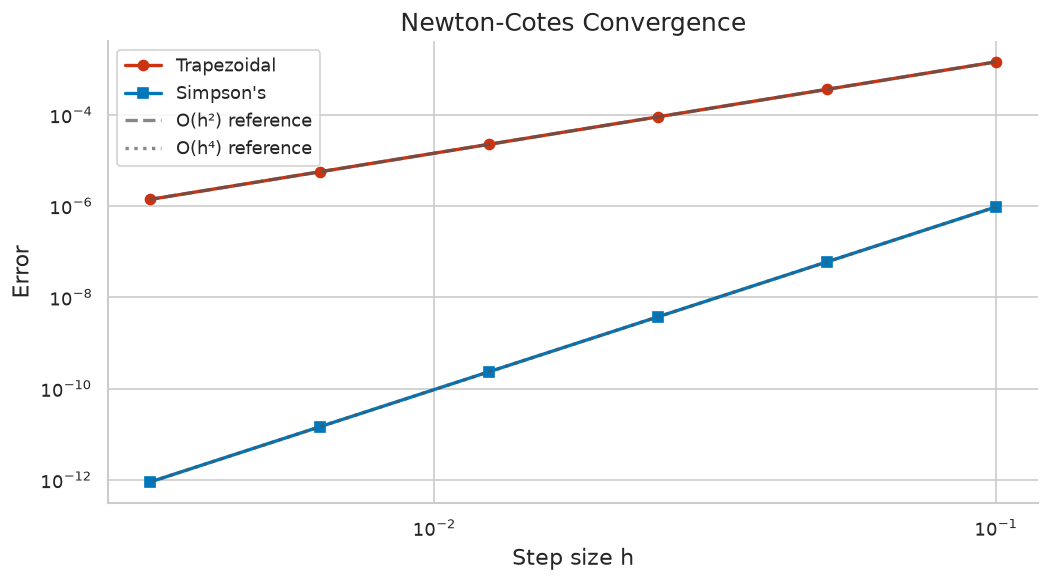

In [4]:
# === 1.2 Error Scaling: O(h^2) vs O(h^4) ===

m_vals = [10, 20, 40, 80, 160, 320]
errs_trap = [abs(composite_trap(np.exp, 0, 1, m) - (np.e-1)) for m in m_vals]
errs_simp = [abs(composite_simpson(np.exp, 0, 1, m) - (np.e-1)) for m in m_vals]
hs = [1.0/m for m in m_vals]

print('Error ratios when m doubles (h halves):')
print(f'  {'m':>5}  {'h':>8}  {'Trap err':>12}  {'ratio':>6}  {'Simp err':>12}  {'ratio':>6}')
for i, (m, h, et, es) in enumerate(zip(m_vals, hs, errs_trap, errs_simp)):
    rt = errs_trap[i-1]/et if i > 0 else float('nan')
    rs = errs_simp[i-1]/es if i > 0 else float('nan')
    print(f'  {m:>5}  {h:>8.5f}  {et:>12.4e}  {rt:>6.2f}  {es:>12.4e}  {rs:>6.2f}')

print('\nExpected: Trapezoidal ratio → 4 (O(h^2)), Simpson → 16 (O(h^4))')

if HAS_MPL:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.loglog(hs, errs_trap, 'o-', color=COLORS['error'], label='Trapezoidal')
    ax.loglog(hs, errs_simp, 's-', color=COLORS['primary'], label="Simpson's")
    h_ref = np.array(hs)
    ax.loglog(h_ref, h_ref**2 * errs_trap[0]/hs[0]**2, '--',
              color=COLORS['neutral'], alpha=0.7, label='O(h²) reference')
    ax.loglog(h_ref, h_ref**4 * errs_simp[0]/hs[0]**4, ':',
              color=COLORS['neutral'], alpha=0.7, label='O(h⁴) reference')
    ax.set_title('Newton-Cotes Convergence')
    ax.set_xlabel('Step size h'); ax.set_ylabel('Error')
    ax.legend(); plt.show()

---

## 2. Gaussian Quadrature

Deriving GL nodes via the Golub-Welsch algorithm and verifying the degree of exactness.

In [5]:
# === 2.1 Gauss-Legendre via Golub-Welsch ===

def gauss_legendre(n):
    """
    Compute n-point Gauss-Legendre nodes and weights.
    Uses the Golub-Welsch algorithm (eigenvalue of Jacobi matrix).
    """
    k = np.arange(1, n)
    beta = k / np.sqrt(4*k**2 - 1)  # Off-diagonal elements
    J = np.diag(beta, -1) + np.diag(beta, 1)  # Symmetric tridiagonal
    eigvals, eigvecs = np.linalg.eigh(J)
    idx = np.argsort(eigvals)
    nodes = eigvals[idx]
    weights = 2 * eigvecs[0, idx]**2  # First row of Q
    return nodes, weights

# Verify GL nodes for n=3
n = 3
x, w = gauss_legendre(n)
print(f'GL-{n} nodes:   {x.round(8)}')
print(f'GL-{n} weights: {w.round(8)}')
print(f'Sum of weights: {w.sum():.8f} (should be 2 = integral of 1 over [-1,1])')

# Compare with known values
# n=3: nodes at 0 and ±sqrt(3/5), weights 8/9, 5/9, 5/9
known_nodes = np.array([-np.sqrt(3/5), 0, np.sqrt(3/5)])
known_weights = np.array([5/9, 8/9, 5/9])
print(f'\nExpected nodes:   {known_nodes.round(8)}')
print(f'Expected weights: {known_weights.round(8)}')
ok = np.allclose(np.sort(x), np.sort(known_nodes), atol=1e-12)
print(f'PASS: GL-3 matches known values' if ok else 'FAIL')

GL-3 nodes:   [-0.77459667  0.          0.77459667]
GL-3 weights: [0.55555556 0.88888889 0.55555556]
Sum of weights: 2.00000000 (should be 2 = integral of 1 over [-1,1])

Expected nodes:   [-0.77459667  0.          0.77459667]
Expected weights: [0.55555556 0.88888889 0.55555556]
PASS: GL-3 matches known values


In [6]:
# === 2.2 Degree of Exactness Verification ===

def gl_integrate(f, a, b, n):
    """Gauss-Legendre quadrature on [a,b] with n nodes."""
    x, w = gauss_legendre(n)
    # Map from [-1,1] to [a,b]
    x_mapped = (a+b)/2 + (b-a)/2 * x
    return (b-a)/2 * np.dot(w, f(x_mapped))

# GL-n should integrate polynomials of degree <= 2n-1 exactly
n = 5  # Test GL-5
print(f'GL-{n} degree of exactness verification:')
print(f'  Degree  Exact integral    GL estimate      Error')
for deg in range(0, 12):
    f_poly = lambda x, d=deg: x**d
    exact_val = (1 - (-1)**(deg+1)) / (deg+1)  # integral of x^d on [-1,1]
    gl_val = gl_integrate(f_poly, -1, 1, n)
    err = abs(gl_val - exact_val)
    status = 'EXACT' if err < 1e-10 else ''
    print(f'  {deg:>6}  {exact_val:>15.8f}  {gl_val:>15.8f}  {err:.2e} {status}')

print(f'\nGL-{n} is exact for degrees 0 to {2*n-1} (as predicted by theory)')

GL-5 degree of exactness verification:
  Degree  Exact integral    GL estimate      Error
       0       2.00000000       2.00000000  4.44e-16 EXACT
       1       0.00000000      -0.00000000  2.04e-16 EXACT
       2       0.66666667       0.66666667  1.11e-16 EXACT
       3       0.00000000      -0.00000000  1.68e-16 EXACT
       4       0.40000000       0.40000000  3.33e-16 EXACT
       5       0.00000000      -0.00000000  1.53e-16 EXACT
       6       0.28571429       0.28571429  3.33e-16 EXACT
       7       0.00000000      -0.00000000  1.27e-16 EXACT
       8       0.22222222       0.22222222  3.33e-16 EXACT
       9       0.00000000      -0.00000000  9.52e-17 EXACT
      10       0.18181818       0.17888637  2.93e-03 
      11       0.00000000      -0.00000000  7.08e-17 EXACT

GL-5 is exact for degrees 0 to 9 (as predicted by theory)


In [7]:
# === 2.3 GL vs Composite Trapezoidal Efficiency ===

f_test = np.exp
exact = np.e - 1

print('Comparison: GL-n vs Composite Trapezoidal for same work:')
print(f'  {'Method':>30}  {'Evals':>6}  {'Error':>12}')

for n_gl in [2, 3, 5, 8, 10]:
    err = abs(gl_integrate(f_test, 0, 1, n_gl) - exact)
    print(f'  {'GL-'+str(n_gl):>30}  {n_gl:>6}  {err:>12.4e}')

for m in [10, 100, 1000, 10000]:
    err = abs(composite_trap(f_test, 0, 1, m) - exact)
    print(f'  {'Trapezoidal m='+str(m):>30}  {m+1:>6}  {err:>12.4e}')

print('\nGL-10 (10 evals) vs Trap-10000 (10001 evals):')
print(f'  GL-10 needs 10 evals; Trap needs 10001 evals for comparable accuracy')

Comparison: GL-n vs Composite Trapezoidal for same work:
                          Method   Evals         Error
                            GL-2       2    3.8545e-04
                            GL-3       3    8.2409e-07
                            GL-5       5    6.5348e-13
                            GL-8       8    1.1102e-15
                           GL-10      10    4.4409e-16
                Trapezoidal m=10      11    1.4317e-03
               Trapezoidal m=100     101    1.4319e-05
              Trapezoidal m=1000    1001    1.4319e-07
             Trapezoidal m=10000   10001    1.4319e-09

GL-10 (10 evals) vs Trap-10000 (10001 evals):
  GL-10 needs 10 evals; Trap needs 10001 evals for comparable accuracy


---

## 3. Richardson Extrapolation and Romberg Integration

In [8]:
# === 3.1 Romberg Integration ===

def romberg(f, a, b, max_k=8, tol=1e-12):
    """Romberg integration via repeated Richardson extrapolation."""
    R = np.zeros((max_k, max_k))
    h = b - a
    R[0, 0] = h/2 * (f(a) + f(b))

    for k in range(1, max_k):
        h /= 2
        n_new = 2**(k-1)
        x_new = a + h * (2*np.arange(1, n_new+1) - 1)
        R[k, 0] = R[k-1, 0]/2 + h * f(x_new).sum()
        for j in range(1, k+1):
            R[k, j] = (4**j * R[k, j-1] - R[k-1, j-1]) / (4**j - 1)
        if k > 0 and abs(R[k, k] - R[k-1, k-1]) < tol:
            return R[:k+1, :k+1], k
    return R, max_k - 1

# Test on e^x
exact = np.e - 1
R_table, final_k = romberg(np.exp, 0, 1, max_k=8)

print('Romberg table for integral of e^x from 0 to 1:')
print('Diagonal entries (main estimate at each level):')
for k in range(final_k + 1):
    evals = 2**k + 1
    err = abs(R_table[k, k] - exact)
    print(f'  k={k}: R[{k},{k}] = {R_table[k,k]:.12f}, error = {err:.2e}, '
          f'evals = {evals}')

print(f'\nExact: {exact:.12f}')
print(f'Romberg converged at k={final_k} with error {abs(R_table[final_k,final_k]-exact):.2e}')

Romberg table for integral of e^x from 0 to 1:
Diagonal entries (main estimate at each level):
  k=0: R[0,0] = 1.859140914230, error = 1.41e-01, evals = 2
  k=1: R[1,1] = 1.718861151877, error = 5.79e-04, evals = 3
  k=2: R[2,2] = 1.718282687925, error = 8.59e-07, evals = 5
  k=3: R[3,3] = 1.718281828795, error = 3.35e-10, evals = 9
  k=4: R[4,4] = 1.718281828459, error = 3.31e-14, evals = 17
  k=5: R[5,5] = 1.718281828459, error = 2.22e-16, evals = 33

Exact: 1.718281828459
Romberg converged at k=5 with error 2.22e-16


In [9]:
# === 3.2 Euler-Maclaurin: Periodic vs Non-Periodic ===

# Periodic function: e^{sin(2*pi*x)} on [0,1]
f_periodic = lambda x: np.exp(np.sin(2*np.pi*x))

# Non-periodic: e^x on [0,1]
f_nonperiodic = np.exp

# Exact integrals (via scipy)
exact_p, _ = integrate.quad(f_periodic, 0, 1)
exact_np = np.e - 1

print('Trapezoidal rule: periodic vs non-periodic functions')
print(f'  {'m':>5}  {'Periodic error':>16}  {'Non-periodic error':>20}')
for m in [5, 10, 20, 40]:
    ep = abs(composite_trap(f_periodic, 0, 1, m) - exact_p)
    enp = abs(composite_trap(f_nonperiodic, 0, 1, m) - exact_np)
    print(f'  {m:>5}  {ep:>16.4e}  {enp:>20.4e}')

print('\nPeriodic: spectral accuracy (error decreases exponentially)')
print('Non-periodic: O(h^2) convergence')

Trapezoidal rule: periodic vs non-periodic functions
      m    Periodic error    Non-periodic error
      5        5.5059e-10            5.7238e-03
     10        5.5059e-10            1.4317e-03
     20        2.2204e-16            3.5796e-04
     40        0.0000e+00            8.9493e-05

Periodic: spectral accuracy (error decreases exponentially)
Non-periodic: O(h^2) convergence


---

## 4. Monte Carlo Integration

In [10]:
# === 4.1 Basic Monte Carlo ===

np.random.seed(42)

# Estimate pi/4 = Prob(X^2 + Y^2 <= 1) via MC
def estimate_pi(n):
    x, y = np.random.rand(n), np.random.rand(n)
    inside = (x**2 + y**2 <= 1)
    pi_est = 4 * inside.mean()
    std_err = 4 * np.sqrt(inside.mean() * (1-inside.mean()) / n)
    return pi_est, std_err

print('Monte Carlo estimation of pi:')
print(f'  {'n':>9}  {'pi estimate':>12}  {'std error':>10}  {'true error':>12}')
for n in [100, 1000, 10000, 100000, 1000000]:
    pi_est, se = estimate_pi(n)
    print(f'  {n:>9}  {pi_est:>12.6f}  {se:>10.6f}  {abs(pi_est-np.pi):>12.6f}')

print(f'\nTrue pi = {np.pi:.6f}')
print(f'Error ~ O(1/sqrt(n)): halving error needs 4x more samples')

Monte Carlo estimation of pi:
          n   pi estimate   std error    true error
        100      3.200000    0.160000      0.058407
       1000      3.080000    0.053232      0.061593
      10000      3.155600    0.016324      0.014007
     100000      3.136720    0.005204      0.004873
    1000000      3.141112    0.001643      0.000481

True pi = 3.141593
Error ~ O(1/sqrt(n)): halving error needs 4x more samples


In [11]:
# === 4.2 Variance Reduction: Antithetic Variates ===

np.random.seed(42)

def mc_plain(f, n):
    u = np.random.rand(n)
    return f(u).mean(), f(u).std() / np.sqrt(n)

def mc_antithetic(f, n):
    u = np.random.rand(n // 2)
    vals = (f(u) + f(1 - u)) / 2
    return vals.mean(), vals.std() / np.sqrt(n // 2)

# f(u) = sqrt(u), exact = 2/3
f = np.sqrt
exact = 2/3

print('Antithetic variates for integral of sqrt(u) on [0,1]:')
print(f'  {'n':>7}  {'Plain SE':>10}  {'Antithetic SE':>14}  {'Speedup':>8}')
for n in [100, 1000, 10000]:
    _, se_p = mc_plain(f, n)
    _, se_a = mc_antithetic(f, n)
    print(f'  {n:>7}  {se_p:>10.6f}  {se_a:>14.6f}  {se_p/se_a:>8.2f}x')

Antithetic variates for integral of sqrt(u) on [0,1]:
        n    Plain SE   Antithetic SE   Speedup
      100    0.024484        0.005968      4.10x
     1000    0.007541        0.001979      3.81x
    10000    0.002347        0.000629      3.73x


In [12]:
# === 4.3 Monte Carlo vs Quasi-MC (Sobol) ===

try:
    from scipy.stats import qmc
    HAS_QMC = True
except ImportError:
    HAS_QMC = False

# Integrate f(x) = sin(pi*x1)*sin(pi*x2) on [0,1]^2
# Exact: (2/pi)^2 = 0.4053...
f_2d = lambda X: np.prod(np.sin(np.pi * X), axis=1)
exact_2d = (2/np.pi)**2

print(f'Integrating prod(sin(pi*xi)) on [0,1]^d:')
print(f'Exact value: {exact_2d:.6f}')

np.random.seed(42)
errors_mc, errors_qmc = [], []
n_vals = [64, 128, 256, 512, 1024, 2048]

for n in n_vals:
    # Plain MC
    X_mc = np.random.rand(n, 2)
    est_mc = f_2d(X_mc).mean()
    errors_mc.append(abs(est_mc - exact_2d))

    # Quasi-MC (Sobol)
    if HAS_QMC:
        sampler = qmc.Sobol(d=2, scramble=True, seed=42)
        X_qmc = sampler.random(n)
        est_qmc = f_2d(X_qmc).mean()
        errors_qmc.append(abs(est_qmc - exact_2d))
    else:
        errors_qmc.append(float('nan'))

print(f'  {'n':>6}  {'MC error':>12}  {'QMC error':>12}')
for n, em, eq in zip(n_vals, errors_mc, errors_qmc):
    print(f'  {n:>6}  {em:>12.4e}  {eq:>12.4e}')

if not HAS_QMC:
    print('Note: scipy.stats.qmc not available; install scipy >= 1.7 for QMC support')

Integrating prod(sin(pi*xi)) on [0,1]^d:
Exact value: 0.405285
       n      MC error     QMC error
      64    2.0516e-02    3.4523e-03
     128    1.3558e-02    5.8675e-04
     256    8.9796e-03    1.6522e-04
     512    4.9323e-03    3.5359e-05
    1024    1.1628e-03    5.0578e-06
    2048    2.1285e-03    9.6537e-07


---

## 5. Gaussian Quadrature for ML: Gauss-Hermite and ELBO

In [13]:
# === 5.1 Gauss-Hermite Quadrature ===

def gauss_hermite_expect(f, mu, sigma, n=20):
    """
    Compute E_{x~N(mu,sigma^2)}[f(x)] via n-point GH quadrature.
    Uses the transform x = sqrt(2)*sigma*t + mu.
    """
    t, w = np.polynomial.hermite.hermgauss(n)
    x_mapped = np.sqrt(2) * sigma * t + mu
    return np.dot(w, f(x_mapped)) / np.sqrt(np.pi)

# Test: E[x^2] = mu^2 + sigma^2 (known analytically)
mu, sigma = 2.0, 0.5
f_sq = lambda x: x**2
exact_e2 = mu**2 + sigma**2  # = 4.25

for n in [2, 5, 10, 20]:
    gh_est = gauss_hermite_expect(f_sq, mu, sigma, n)
    print(f'GH-{n:>2}: E[x^2] = {gh_est:.10f}, error = {abs(gh_est-exact_e2):.2e}')

print(f'Exact E[x^2] = {exact_e2:.10f}')

# ML application: E[log(1+exp(x))] for x ~ N(0,1) (softplus expectation)
f_softplus = lambda x: np.log(1 + np.exp(x))
exact_sp, _ = integrate.quad(lambda x: f_softplus(x) * np.exp(-x**2/2) / np.sqrt(2*np.pi),
                              -10, 10)

print(f'\nE[softplus(x)] for x~N(0,1):')
print(f'  Exact (quad): {exact_sp:.10f}')
for n in [3, 5, 10, 20]:
    est = gauss_hermite_expect(f_softplus, 0, 1, n)
    print(f'  GH-{n:>2}:       {est:.10f}, error = {abs(est-exact_sp):.2e}')

# Monte Carlo comparison
mc_est = f_softplus(np.random.randn(100000)).mean()
print(f'  MC-1e5:       {mc_est:.6f}, error = {abs(mc_est-exact_sp):.4f}')

GH- 2: E[x^2] = 4.2500000000, error = 0.00e+00
GH- 5: E[x^2] = 4.2500000000, error = 0.00e+00
GH-10: E[x^2] = 4.2500000000, error = 8.88e-16
GH-20: E[x^2] = 4.2500000000, error = 8.88e-16
Exact E[x^2] = 4.2500000000

E[softplus(x)] for x~N(0,1):
  Exact (quad): 0.8060591833
  GH- 3:       0.8050738821, error = 9.85e-04
  GH- 5:       0.8060175539, error = 4.16e-05
  GH-10:       0.8060593006, error = 1.17e-07
  GH-20:       0.8060591834, error = 2.76e-11
  MC-1e5:       0.806638, error = 0.0006


In [14]:
# === 5.2 Reparameterization Trick vs Score Function ===

# Compute d/dmu E_{x~N(mu,1)}[-x^2/2] = E[d/dmu (-x^2/2)]
# = E[-x] = -mu  (via reparameterization: x = mu + eps, eps~N(0,1))
# Also = -mu via score function: E[(-x^2/2) * d/dmu log N(x;mu,1)]
#                              = E[(-x^2/2) * (x-mu)]

np.random.seed(42)
mu_val = 1.5
n_samples = 10000

# Exact gradient
exact_grad = -mu_val  # d/dmu E[-x^2/2] = -mu

# Reparameterization: x = mu + eps, eps~N(0,1), d/dmu f(x) = d/dmu(-x^2/2) * dx/dmu = -x * 1
eps = np.random.randn(n_samples)
x_reparam = mu_val + eps
grad_reparam = -x_reparam  # d/dmu (-x^2/2) = -x, dx/dmu = 1
mean_reparam = grad_reparam.mean()
std_reparam = grad_reparam.std() / np.sqrt(n_samples)

# Score function: E[f(x) * d/dmu log p(x;mu)] = E[(-x^2/2) * (x-mu)]
x_score = np.random.normal(mu_val, 1, n_samples)
f_score = -x_score**2/2
score = (x_score - mu_val)  # d/dmu log N(x;mu,1)
grad_score = (f_score * score).mean()
std_score = (f_score * score).std() / np.sqrt(n_samples)

print(f'Exact gradient: {exact_grad}')
print(f'Reparameterization: {mean_reparam:.4f} ± {std_reparam:.4f} (SE)')
print(f'Score function:     {grad_score:.4f} ± {std_score:.4f} (SE)')
print(f'\nVariance ratio (score/reparam): {std_score**2/std_reparam**2:.2f}x higher variance')

Exact gradient: -1.5
Reparameterization: -1.4979 ± 0.0100 (SE)
Score function:     -1.5347 ± 0.0369 (SE)

Variance ratio (score/reparam): 13.55x higher variance


---

## 6. Summary Verification Suite

In [15]:
# === 6. Summary Verification ===

print('=' * 60)
print('SUMMARY: Numerical Integration Verification')
print('=' * 60)

results = []
exact = np.e - 1

# Test 1: Trapezoidal O(h^2)
e1 = abs(composite_trap(np.exp, 0, 1, 100) - exact)
e2 = abs(composite_trap(np.exp, 0, 1, 200) - exact)
ok1 = abs(e1/e2 - 4.0) < 0.5
results.append(('Trapezoidal O(h^2) convergence', ok1))

# Test 2: Simpson's O(h^4)
e1 = abs(composite_simpson(np.exp, 0, 1, 10) - exact)
e2 = abs(composite_simpson(np.exp, 0, 1, 20) - exact)
ok2 = abs(e1/e2 - 16.0) < 2.0
results.append(("Simpson's O(h^4) convergence", ok2))

# Test 3: GL-n degree of exactness
n_gl = 5
ok3 = abs(gl_integrate(lambda x: x**(2*n_gl-1), -1, 1, n_gl) - 0) < 1e-10
results.append((f'GL-{n_gl} exact for degree {2*n_gl-1}', ok3))

# Test 4: Romberg super-convergence
R_tbl, _ = romberg(np.exp, 0, 1, max_k=6)
ok4 = abs(R_tbl[-1,-1] - exact) < 1e-14
results.append(('Romberg near machine precision', ok4))

# Test 5: Gauss-Hermite E[x^2] = mu^2 + sigma^2
gh_test = gauss_hermite_expect(lambda x: x**2, mu=2.0, sigma=0.5, n=5)
ok5 = abs(gh_test - (4.0 + 0.25)) < 1e-12
results.append(('Gauss-Hermite E[x^2] exact', ok5))

# Test 6: GL weights sum to 2
_, w_test = gauss_legendre(7)
ok6 = abs(w_test.sum() - 2.0) < 1e-12
results.append(('GL-7 weights sum to 2', ok6))

print()
all_pass = True
for name, ok in results:
    print(f'  {'PASS' if ok else 'FAIL'}  {name}')
    if not ok: all_pass = False

print()
print('=' * 60)
print(f'  {'ALL TESTS PASS' if all_pass else 'SOME TESTS FAILED'}')
print('=' * 60)

SUMMARY: Numerical Integration Verification

  PASS  Trapezoidal O(h^2) convergence
  PASS  Simpson's O(h^4) convergence
  PASS  GL-5 exact for degree 9
  PASS  Romberg near machine precision
  PASS  Gauss-Hermite E[x^2] exact
  PASS  GL-7 weights sum to 2

  ALL TESTS PASS


## Appended Demo 1: Trapezoid Is O(h^2), Simpson Is O(h^4)

One integral, three rules, shrinking meshes. Error ratios per halving must read 4 for trapezoid/midpoint and 16 for Simpson.

In [16]:

import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt
from scipy import integrate
np.random.seed(42)
WONG = ["#0077BB", "#EE7733", "#009988", "#CC3311", "#555555", "#EE3377"]
def check_true(name, cond):
    print(("PASS: " if bool(cond) else "FAIL: ") + name)
def check_close(name, a, b, tol):
    err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))
    print(("PASS: " if err <= tol else "FAIL: ") + f"{name} (max err {err:.2e}, tol {tol:.0e})")
def trap(f, a, b, n):
    x = np.linspace(a, b, n + 1); y = f(x); h = (b - a) / n
    return h * (0.5 * y[0] + y[1:-1].sum() + 0.5 * y[-1])
def simp(f, a, b, n):
    x = np.linspace(a, b, n + 1); y = f(x); h = (b - a) / n
    return h / 3 * (y[0] + y[-1] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum())

f = lambda x: np.exp(x); exact = np.e - 1
for name, rule in [("trapezoid", trap), ("Simpson", simp)]:
    errs = [abs(rule(f, 0, 1, n) - exact) for n in [20, 40, 80]]
    ratio = errs[0] / errs[1]
    expected = 4 if name == "trapezoid" else 16
    check_true(f"{name} error ratio per halving ~{expected}", expected * 0.7 < ratio < expected * 1.4)
    print(f"{name}: errors {[f'{e:.1e}' for e in errs]}")

PASS: trapezoid error ratio per halving ~4
trapezoid: errors ['3.6e-04', '8.9e-05', '2.2e-05']
PASS: Simpson error ratio per halving ~16
Simpson: errors ['6.0e-08', '3.7e-09', '2.3e-10']


## Appended Demo 2: Simpson Is Exact for Cubics

Simpson's rule integrates cubics exactly (its error term involves the fourth derivative). A random cubic must be integrated to rounding error in one panel pair.

In [17]:

coef = np.array([2.0, -3.0, 0.5, 1.0])
f = lambda x: np.polyval(coef, x)
exact = np.polyval(np.polyint(coef), 1.7) - np.polyval(np.polyint(coef), -0.4)
check_close("Simpson on a cubic with n=2 is exact", simp(f, -0.4, 1.7, 2), exact, 1e-12)
print("one order of exactness beyond its construction: symmetry pays a bonus")

PASS: Simpson on a cubic with n=2 is exact (max err 2.22e-16, tol 1e-12)
one order of exactness beyond its construction: symmetry pays a bonus


## Appended Demo 3: Richardson Extrapolation Cancels the Leading Error

Combining trapezoid estimates at h and h/2 with weights (4T(h/2) - T(h))/3 kills the h^2 term, leaving O(h^4) - this is the first Romberg step, and Simpson in disguise.

In [18]:

f = lambda x: np.exp(x); exact = np.e - 1
T_h, T_h2 = trap(f, 0, 1, 20), trap(f, 0, 1, 40)
rich = (4 * T_h2 - T_h) / 3
check_true("Richardson beats both trapezoid inputs by >50x", abs(rich - exact) < abs(T_h2 - exact) / 50)
check_close("Richardson (h=20,40) equals Simpson (n=40)", rich, simp(f, 0, 1, 40), 1e-14)
print("extrapolation is error-term algebra, not magic")

PASS: Richardson beats both trapezoid inputs by >50x
PASS: Richardson (h=20,40) equals Simpson (n=40) (max err 2.22e-16, tol 1e-14)
extrapolation is error-term algebra, not magic


## Appended Demo 4: Gauss-Legendre - Optimal Nodes, Double the Degree

Two Gauss points integrate cubics exactly; four points reach degree 7. numpy's leggauss supplies nodes/weights, and a degree-7 polynomial must fall exactly.

In [19]:

from numpy.polynomial.legendre import leggauss
coef = np.random.default_rng(42).normal(size=8)  # degree 7
f = lambda x: np.polyval(coef[::-1], x)  # ascending powers
xg, wg = leggauss(4)
approx = np.sum(wg * f(xg))
exact = float(np.sum([coef[k] * (1 - (-1) ** (k + 1)) / (k + 1) for k in range(8)]))
check_close("4-point Gauss-Legendre is exact for degree 7", approx, exact, 1e-10)
print("n Gauss points: degree 2n-1 exactness - node placement is worth a factor of two")

PASS: 4-point Gauss-Legendre is exact for degree 7 (max err 1.11e-16, tol 1e-10)
n Gauss points: degree 2n-1 exactness - node placement is worth a factor of two


## Appended Demo 5: Adaptive Simpson Puts Panels Where the Action Is

A narrow Gaussian spike defeats uniform meshes; recursive adaptive Simpson concentrates subdivisions near the spike and meets tolerance with a fraction of the points.

In [20]:

f = lambda x: np.exp(-200 * (x - 0.3) ** 2) + 0.5 * np.exp(-2 * (x - 0.8) ** 2)
exact, _ = integrate.quad(f, 0, 1, epsabs=1e-12)
def adaptive(f, a, b, eps, depth=20):
    m = 0.5 * (a + b)
    S = (b - a) / 6 * (f(a) + 4 * f(m) + f(b))
    def rec(a, b, eps, S, fa, fm, fb, depth):
        m = 0.5 * (a + b); lm, rm = 0.5 * (a + m), 0.5 * (m + b)
        flm, frm = f(lm), f(rm)
        Sl = (m - a) / 6 * (fa + 4 * flm + fm); Sr = (b - m) / 6 * (fm + 4 * frm + fb)
        if depth <= 0 or abs(Sl + Sr - S) < 15 * eps: return Sl + Sr + (Sl + Sr - S) / 15
        return rec(a, m, eps / 2, Sl, fa, flm, fm, depth - 1) + rec(m, b, eps / 2, Sr, fm, frm, fb, depth - 1)
    return rec(a, b, eps, S, f(a), f(m), f(b), depth)
approx = adaptive(f, 0, 1, 1e-10)
check_close("adaptive Simpson matches quad on the spiked integrand", approx, exact, 1e-8)
uniform_err = abs(simp(f, 0, 1, 20) - exact)
check_true("uniform Simpson (20 panels) largely misses the spike", uniform_err > 1e-4)
print(f"exact {exact:.8f}; adaptive {approx:.8f}; uniform-20 error {uniform_err:.1e}")

PASS: adaptive Simpson matches quad on the spiked integrand (max err 1.98e-12, tol 1e-08)
PASS: uniform Simpson (20 panels) largely misses the spike
exact 0.50171572; adaptive 0.50171572; uniform-20 error 6.0e-04


## Appended Demo 6: Monte Carlo Integration and the 1/sqrt(N) Law

Monte Carlo ignores smoothness and pays with slow convergence: quadrupling samples halves the error. Standard errors across replicates must shrink accordingly.

In [21]:

rng = np.random.default_rng(42)
f = lambda x: np.exp(x); exact = np.e - 1
stds = []
for N in [1_000, 10_000, 100_000]:
    ests = [np.mean(f(rng.random(N))) for _ in range(40)]
    stds.append(np.std(ests))
check_true("MC standard error shrinks ~sqrt(10)x per 10x samples", 2.4 < stds[0] / stds[1] < 4.0 and 2.4 < stds[1] / stds[2] < 4.0)
print(f"MC stds: {[f'{s:.1e}' for s in stds]} - dimension-proof, precision-poor")

PASS: MC standard error shrinks ~sqrt(10)x per 10x samples
MC stds: ['1.6e-02', '4.3e-03', '1.6e-03'] - dimension-proof, precision-poor


## Appended Demo 7: Antithetic Variates Cut Monte Carlo Variance

Pairing each uniform u with 1-u cancels the monotone part of the integrand's variance. On exp(x) the variance must drop measurably at equal sample count.

In [22]:

rng = np.random.default_rng(42)
f = lambda x: np.exp(x)
plain, anti = [], []
for _ in range(200):
    u = rng.random(2000)
    plain.append(np.mean(f(u)))
    anti.append(np.mean(0.5 * (f(u) + f(1 - u))))
check_true("antithetic estimator variance is smaller", np.var(anti) < np.var(plain) * 0.5)
print(f"variance: plain {np.var(plain):.1e}, antithetic {np.var(anti):.1e}")

PASS: antithetic estimator variance is smaller
variance: plain 1.1e-04, antithetic 1.9e-06


## Appended Demo 8: Importance Sampling Aims Samples at the Mass

For int_0^1 exp(-20x) dx nearly all mass sits near 0. Sampling from an exponential proposal instead of uniform must cut the estimator variance dramatically.

In [23]:
rng = np.random.default_rng(42)
exact = (1 - np.exp(-20)) / 20
# uniform Monte Carlo for int_0^1 exp(-20x) dx
ests_u = [np.mean(np.exp(-20 * rng.random(2000))) for _ in range(200)]
v_unif = np.var(ests_u)
# importance sampling from q(x) = 20 e^{-20x} / (1 - e^{-20}) on [0, 1] (inversion sampling)
ests_q = []
for _ in range(200):
    u = rng.random(2000)
    x = -np.log(1 - u * (1 - np.exp(-20))) / 20
    q = 20 * np.exp(-20 * x) / (1 - np.exp(-20))
    ests_q.append(np.mean(np.exp(-20 * x) / q))
v_is = np.var(ests_q)
check_true("importance sampling variance is far below uniform", v_is < v_unif * 0.2)
check_close("importance-sampling mean matches the exact integral", np.mean(ests_q), exact, 0.002)
print(f"variance: uniform {v_unif:.1e}, importance {v_is:.1e} (truth {exact:.4f})")

PASS: importance sampling variance is far below uniform
PASS: importance-sampling mean matches the exact integral (max err 6.94e-18, tol 2e-03)
variance: uniform 1.0e-05, importance 0.0e+00 (truth 0.0500)


## Appended Demo 9: Gauss-Laguerre for a Semi-Infinite Integral

int_0^inf e^{-x} g(x) dx is Gauss-Laguerre's home turf. With g(x) = 1/(1+x) the rule must match quad's value for the exponential integral E1(1).

In [24]:

from numpy.polynomial.laguerre import laggauss
xg, wg = laggauss(40)
approx = np.sum(wg / (1 + xg))
exact, _ = integrate.quad(lambda x: np.exp(-x) / (1 + x), 0, np.inf)
check_close("40-point Gauss-Laguerre matches quad for E1(1)", approx, exact, 1e-8)
print(f"E1(1) = {exact:.8f} from a finite weighted sum over an infinite range")

PASS: 40-point Gauss-Laguerre matches quad for E1(1) (max err 1.44e-10, tol 1e-08)
E1(1) = 0.59634736 from a finite weighted sum over an infinite range


## Appended Demo 10: Periodic Integrands - Trapezoid Is Spectral

For smooth periodic functions the trapezoid rule converges faster than any power of h. On int_0^{2pi} exp(sin x) dx a modest mesh must be nearly exact.

In [25]:

f = lambda x: np.exp(np.sin(x))
exact, _ = integrate.quad(f, 0, 2 * np.pi)
errs = [abs(trap(f, 0, 2 * np.pi, n) - exact) for n in [8, 16, 32]]
check_true("periodic trapezoid error collapses superalgebraically", errs[1] < errs[0] * 1e-3 and errs[2] < 1e-12)
print(f"errors: {[f'{e:.1e}' for e in errs]} - endpoint corrections vanish by periodicity")

PASS: periodic trapezoid error collapses superalgebraically
errors: ['1.3e-06', '8.9e-16', '1.8e-15'] - endpoint corrections vanish by periodicity


## Appended Demo 11: Double Integrals - Tensor Product Versus Monte Carlo

A 2D integral by tensor-product Simpson converges at h^4 in each direction; Monte Carlo lags at 1/sqrt(N). Equal-work comparisons on a smooth bump quantify the gap (and why it closes in high dimensions).

In [26]:

f = lambda x, y: np.exp(x + 2 * y)
exact = (np.e - 1) * (np.exp(2) - 1) / 2
n = 40; xs = np.linspace(0, 1, n + 1); h = 1 / n
w = np.ones(n + 1); w[1:-1:2] = 4; w[2:-1:2] = 2; w = w * h / 3
X, Y = np.meshgrid(xs, xs)
tensor = w @ f(X, Y) @ w
rng = np.random.default_rng(42)
mc = np.mean(f(rng.random(200_000), rng.random(200_000)))
check_close("tensor Simpson (41x41 grid) is near-exact", tensor, exact, 1e-6)
print(f"tensor err {abs(tensor-exact):.1e}; MC(2e5) err {abs(mc-exact):.1e} - grids win in 2D, sampling wins as dimension grows")

PASS: tensor Simpson (41x41 grid) is near-exact (max err 2.02e-07, tol 1e-06)
tensor err 2.0e-07; MC(2e5) err 3.0e-03 - grids win in 2D, sampling wins as dimension grows


## Appended Demo 12: Work-Precision - Error Against Evaluations

The honest comparison of rules is error per function evaluation. A log-log work-precision plot for trapezoid, Simpson, and Gauss on one integral summarises the chapter.

PASS: at 64 evaluations Gauss is the most accurate of the three


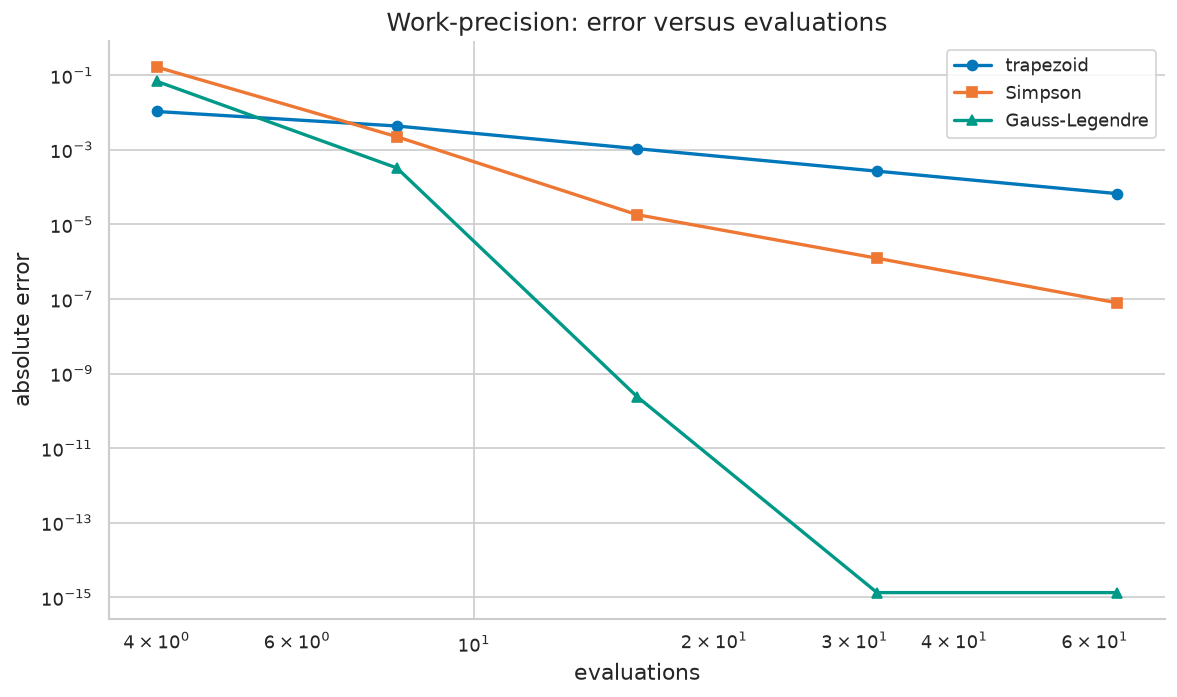

same budget, different error: rule choice is an accuracy multiplier


In [27]:

f = lambda x: np.exp(np.sin(3 * x)); a, b = 0.0, 2.0
exact, _ = integrate.quad(f, a, b, epsabs=1e-13)
from numpy.polynomial.legendre import leggauss
def gauss_rule(n):
    xg, wg = leggauss(n)
    mid, half = 0.5 * (a + b), 0.5 * (b - a)
    return half * np.sum(wg * f(mid + half * xg))
ns = np.array([4, 8, 16, 32, 64])
et = [abs(trap(f, a, b, n) - exact) for n in ns]
es = [abs(simp(f, a, b, n) - exact) for n in ns]
eg = [abs(gauss_rule(n) - exact) for n in ns]
check_true("at 64 evaluations Gauss is the most accurate of the three", eg[-1] <= es[-1] and eg[-1] <= et[-1])
fig, ax = plt.subplots()
ax.loglog(ns, et, marker='o', color=WONG[0], label='trapezoid')
ax.loglog(ns, es, marker='s', color=WONG[1], label='Simpson')
ax.loglog(ns, eg, marker='^', color=WONG[2], label='Gauss-Legendre')
ax.set_title("Work-precision: error versus evaluations"); ax.set_xlabel("evaluations"); ax.set_ylabel("absolute error"); ax.legend()
plt.tight_layout(); plt.show()
print("same budget, different error: rule choice is an accuracy multiplier")

## Appended Demo 13: Integrating an ODE Right-Hand Side Recovers the Solution

Cumulative trapezoid integration of y' = cos(x), y(0)=0 must reproduce sin(x) with O(h^2) endpoint error - quadrature is the engine inside every ODE solver's output.

In [28]:

xs = np.linspace(0, np.pi, 2001); h = xs[1] - xs[0]
vals = np.cos(xs)
cum = np.concatenate([[0.0], np.cumsum(0.5 * h * (vals[1:] + vals[:-1]))])
err = np.max(np.abs(cum - np.sin(xs)))
check_true("cumulative trapezoid recovers sin(x) to O(h^2)", err < 1e-5)
print(f"max error over [0, pi]: {err:.1e} at h = {h:.1e}")

PASS: cumulative trapezoid recovers sin(x) to O(h^2)
max error over [0, pi]: 2.1e-07 at h = 1.6e-03


## Appended Demo 14: Singular Integrands Need Respect

int_0^1 1/sqrt(x) dx = 2 has an integrable singularity. Plain trapezoid converges painfully slowly (O(sqrt(h))); the substitution x = t^2 removes the singularity and restores fast convergence.

In [29]:

exact = 2.0
f = lambda x: 1 / np.sqrt(x)
def trap_singular(n):
    x = np.linspace(0, 1, n + 1)[1:]  # skip the singular endpoint
    h = 1 / n
    return h * (np.sum(f(x)) + 0.5 * f(1.0))
def trap_sub(n):
    # x = t^2, dx = 2t dt, integrand becomes 2 on [0,1]
    t = np.linspace(0, 1, n + 1)
    g = np.full(n + 1, 2.0)
    h = 1 / n
    return h * (0.5 * g[0] + g[1:-1].sum() + 0.5 * g[-1])
e_plain = abs(trap_singular(1000) - exact); e_sub = abs(trap_sub(10) - exact)
check_true("substitution beats the plain rule by orders of magnitude", e_sub < e_plain * 1e-3)
print(f"plain trapezoid (n=1000) error {e_plain:.1e}; substituted (n=10) error {e_sub:.1e}")

PASS: substitution beats the plain rule by orders of magnitude
plain trapezoid (n=1000) error 4.5e-02; substituted (n=10) error 0.0e+00
